# dubois-charts: a tutorial

In 1900, W.E.B. Du Bois and his students at Atlanta University drew 63
charts of Black life in Georgia and the United States for the Paris
Exposition: flat, bold colour, hand lettering, and shapes -- spirals,
folded bars, maps -- that no one had used for data before.
**dubois-charts** draws charts in that style with matplotlib, from your
own data.

This notebook goes through every kind of chart. Its numbers are made up,
except where it says where they come from: the point is what each chart
does with data of a realistic shape -- a pandas table, Census county
codes, dates, long names, many rows.

dubois-charts isn't on PyPI yet; install it from its repository (private
for now, so with access to it):

```
pip install git+https://github.com/shalinialisha/dubois-charts.git
```

In [1]:
import dubois_charts as dc
import pandas as pd

# Show the charts here as they're drawn, at 72 dots per inch (saved
# files use each chart's own dpi, 150 by default).
%config InlineBackend.print_figure_kwargs = {'bbox_inches': None, 'dpi': 72}

## A first chart

Every chart function takes your data and returns a matplotlib `Figure`.
There's nothing to tune: titles wrap, labels shrink or wrap to fit, and
numbers go where there's room for them.

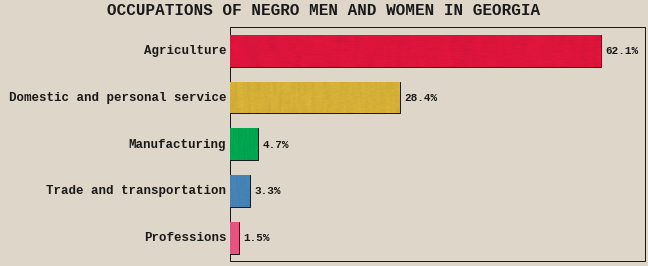

In [2]:
fig = dc.bar_chart(
    categories=['Agriculture', 'Domestic and personal service', 'Manufacturing',
                'Trade and transportation', 'Professions'],
    values=[62.1, 28.4, 4.7, 3.3, 1.5],
    title='Occupations of Negro men and women in Georgia',
    value_format='{:.1f}%',
    sort_descending=True,
)

To keep it, `fig.savefig('occupations.png')` -- or pass
`save_path='occupations.png'` to the chart function. The figure is an
ordinary matplotlib figure, so anything matplotlib does with one still
works.

Numbers print as plain numbers unless you say otherwise: `value_format`
takes a Python format string, `'{:.1f}%'` here, `'${:,.0f}'` for dollars.

## Your data as it is

Lists, tuples, numpy arrays, pandas Series and DataFrames all work. A
DataFrame goes to `bar_chart` or `stacked_area_chart` as one series per
column; a Series goes to `pie_chart`, `snake_chart` or the maps as
index -> value.

In [3]:
tenure = pd.DataFrame(
    {'Owners': [8, 13, 18, 22, 25],
     'Tenants': [55, 52, 48, 44, 40],
     'Wage labourers': [37, 35, 34, 34, 35]},
    index=[1890, 1900, 1910, 1920, 1930],
)
tenure

,Owners,Tenants,Wage labourers
1890,8,55,37
1900,13,52,35
1910,18,48,34
1920,22,44,34
1930,25,40,35


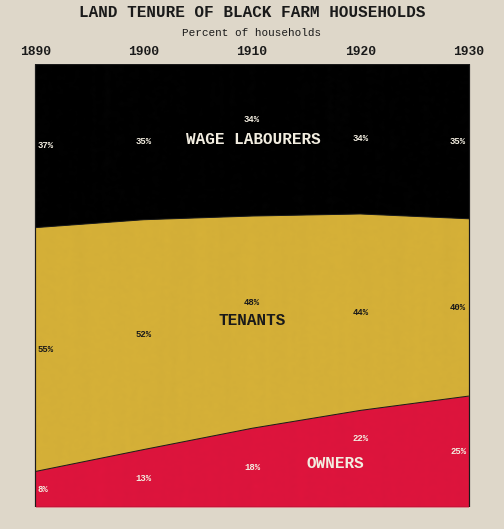

In [4]:
fig = dc.stacked_area_chart(
    tenure.index, tenure,
    title='Land tenure of Black farm households',
    subtitle='Percent of households',
)

The bands stack in column order, bottom to top. Every column adds up to
100, so the values get a percent sign by themselves; for anything else,
pass `value_format`. Each band's name goes inside it if it fits there --
somewhere along the band, wherever it has the room -- and into a legend
below the chart if not.

The same table, the other way round, as grouped bars:

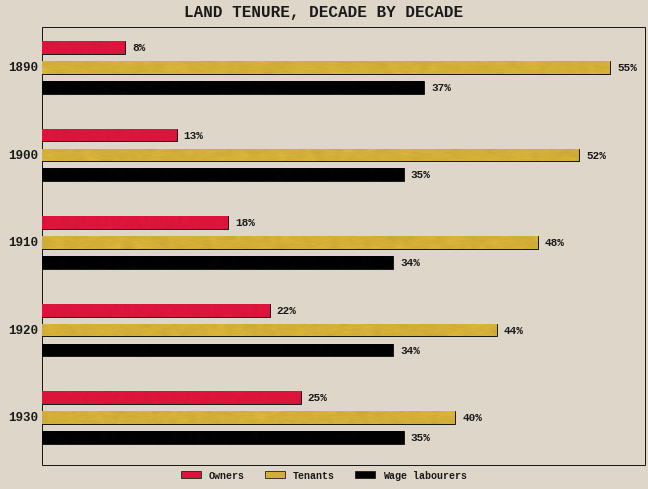

In [5]:
fig = dc.bar_chart(
    [str(year) for year in tenure.index], tenure,
    title='Land tenure, decade by decade',
    value_format='{:.0f}%',
)

## Bars both ways

Negative values grow left from a shared zero line, positive ones right:

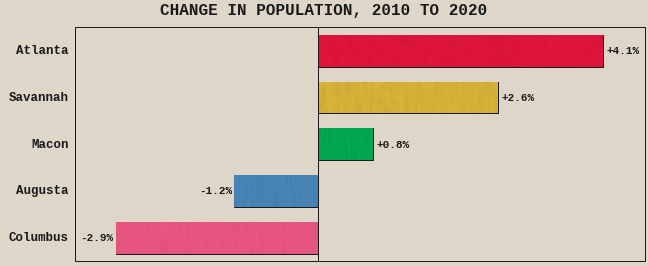

In [6]:
change = pd.Series({'Atlanta': 4.1, 'Savannah': 2.6, 'Macon': 0.8,
                    'Augusta': -1.2, 'Columbus': -2.9})
fig = dc.bar_chart(change.index, change,
                   title='Change in population, 2010 to 2020',
                   value_format='{:+.1f}%')

## Dates

The area chart's x can be numbers, text or dates -- `datetime`, pandas
Timestamps, numpy `datetime64`. Dates are placed by time, so gaps show
truthfully, and labelled as compactly as they allow: "Jan 2023" for
monthly data, not "2023-01-01 00:00:00". With more points than there's
room to label, the labels thin out -- always keeping the first and the
last -- and the numbers go only where a label is.

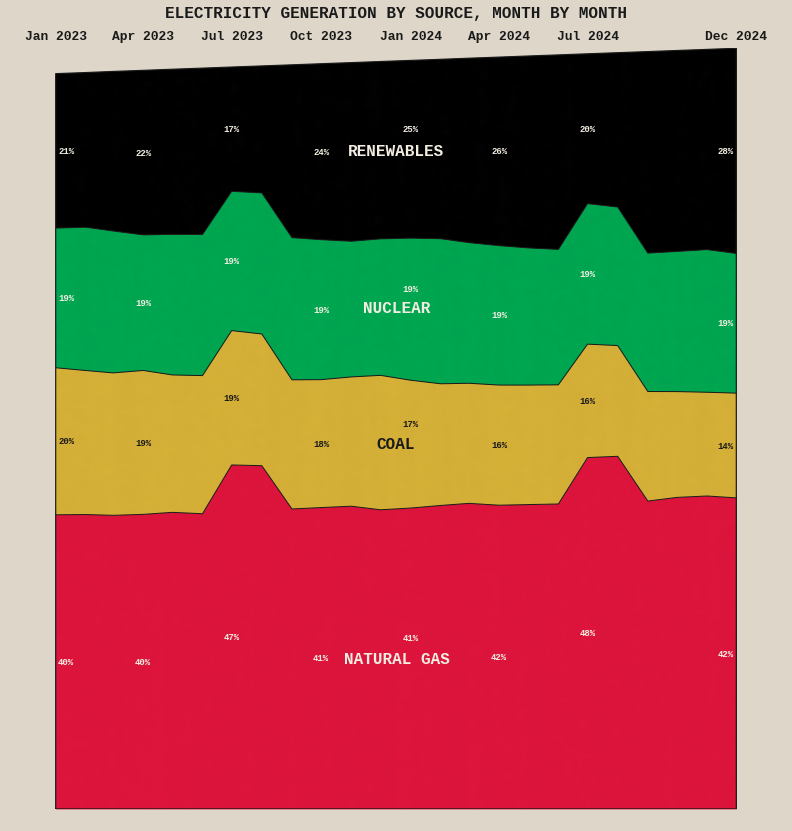

In [7]:
months = pd.date_range('2023-01-01', periods=24, freq='MS')
sources = pd.DataFrame({
    'Natural gas': [40 + 6 * (m.month in (7, 8)) + i * 0.1 for i, m in enumerate(months)],
    'Coal': [20 - i * 0.25 for i in range(24)],
    'Nuclear': [19] * 24,
    'Renewables': [21 + i * 0.3 - 6 * (m.month in (7, 8)) for i, m in enumerate(months)],
}, index=months)
fig = dc.stacked_area_chart(sources.index, sources,
                            title='Electricity generation by source, month by month',
                            value_format='{:.0f}%')

## Two sides: the butterfly chart

Two sets of bars growing out from one column of names, to compare two
groups category by category.

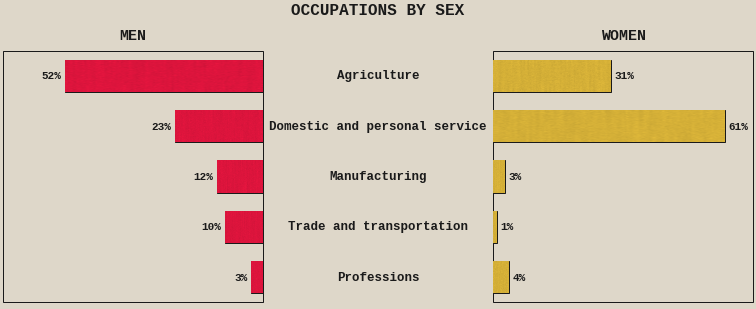

In [8]:
fig = dc.butterfly_chart(
    categories=['Agriculture', 'Domestic and personal service', 'Manufacturing',
                'Trade and transportation', 'Professions'],
    left_values=[52, 23, 12, 10, 3],
    right_values=[31, 61, 3, 1, 4],
    left_label='Men', right_label='Women',
    title='Occupations by sex',
    value_format='{:.0f}%',
)

## Growth: the spiral

A line wound round a centre: each point's place in the series sets its
angle, clockwise from the top, and the larger its value, the farther it
is from the centre -- so a growing series opens out into a spiral. (Du
Bois coiled a bar this way in his plate of Georgia's city and rural
population, where the 734,952 people of the country and villages made a
bar far too long for the page.)

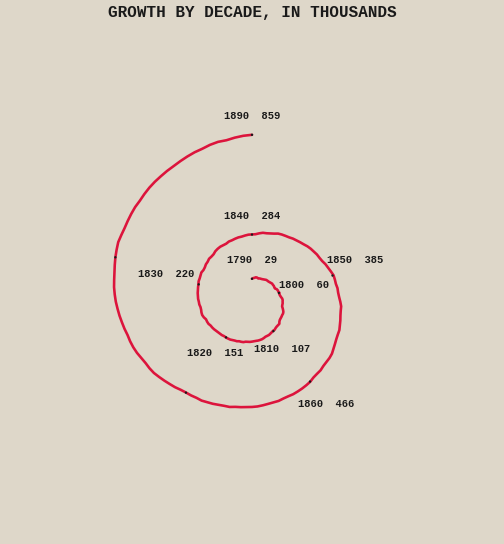

In [9]:
fig = dc.spiral_chart(
    categories=[1790, 1800, 1810, 1820, 1830, 1840, 1850, 1860, 1870, 1880, 1890],
    values=[29, 60, 107, 151, 220, 284, 385, 466, 545, 725, 859],
    title='Growth by decade, in thousands',
)

More points wind the spiral tighter (about seven a turn; `revolutions=`
sets it). When the turns are too close for a label beside every point,
the labels go where they fit -- mostly on the outer turns -- and only the
first, last, highest and lowest points get a leader line from deep
inside.

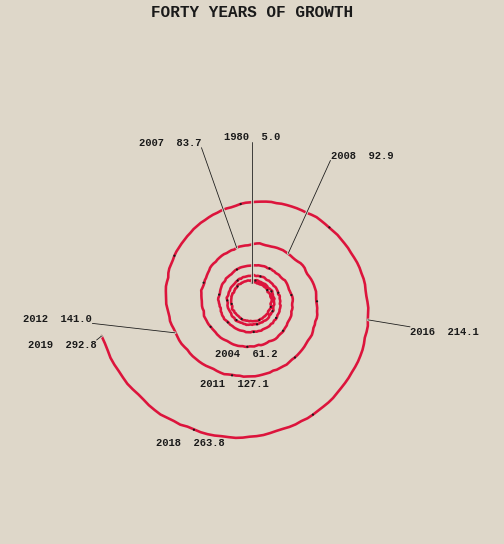

In [10]:
fig = dc.spiral_chart([str(year) for year in range(1980, 2020)],
                      [round(5 * 1.11 ** i, 1) for i in range(40)],
                      title='Forty years of growth')

## One long scale, folded: the snake chart

A single bar too long for the page, folded back and forth into rows.
Each row's scale is marked at its ends, so it still reads as one bar.

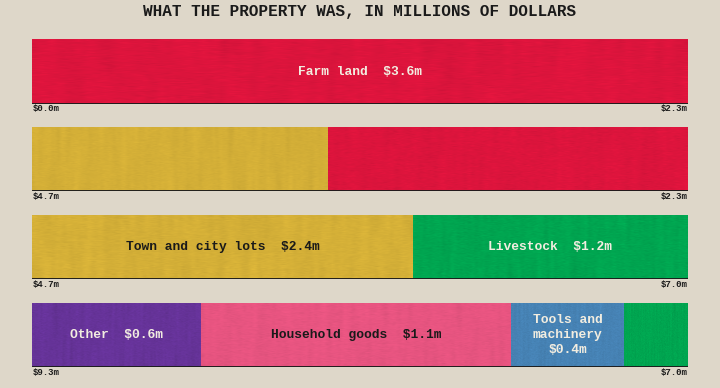

In [11]:
property_value = pd.Series({'Farm land': 3.6, 'Town and city lots': 2.4,
                            'Livestock': 1.2, 'Tools and machinery': 0.4,
                            'Household goods': 1.1, 'Other': 0.6})
fig = dc.snake_chart(property_value, n_rows=4,
                     title='What the property was, in millions of dollars',
                     value_format='${:.1f}m')

## Parts of a whole: the pie chart

Slices too thin for their names get them outside, with a line to the
slice; the lines don't cross each other or the pie.

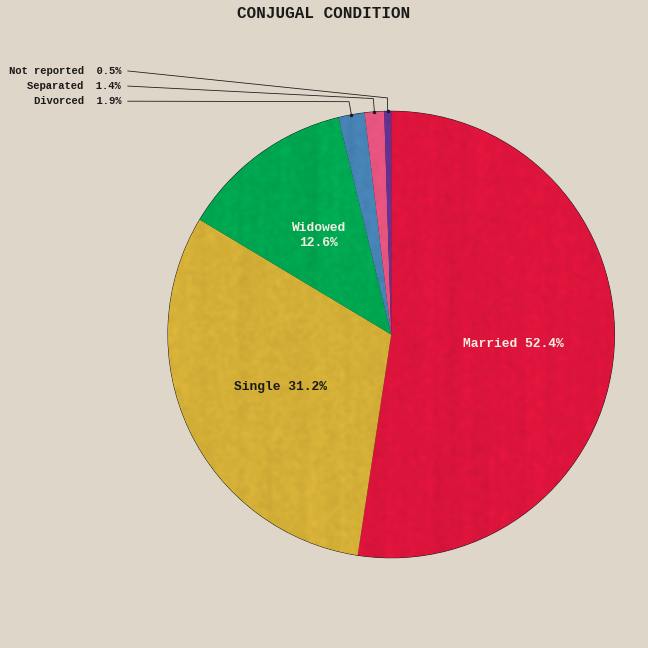

In [12]:
marital = pd.Series({'Married': 52.4, 'Single': 31.2, 'Widowed': 12.6,
                     'Divorced': 1.9, 'Separated': 1.4, 'Not reported': 0.5})
fig = dc.pie_chart(marital, title='Conjugal condition', value_format='{:.1f}%')

## Maps of counties

`county_map_chart` shades counties by value in a few classes, light to
dark, and names the highest and lowest. Georgia is the default, as on Du
Bois's own maps; the names can be written any common way ("DeKalb", "De
Kalb County", "DeKalb County, Georgia").

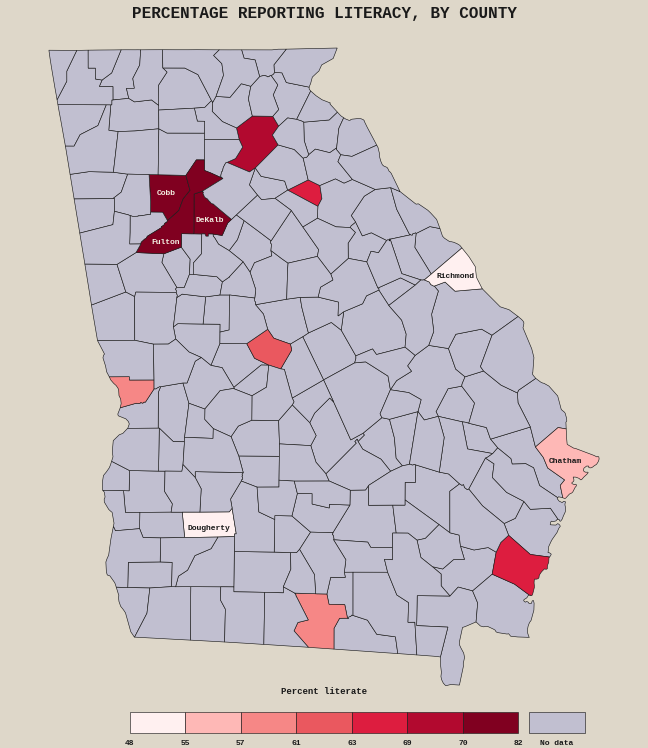

In [13]:
literacy = {'Fulton': 82, 'DeKalb': 74, 'Chatham': 55, 'Bibb': 61, 'Cobb': 70,
            'Richmond': 48, 'Muscogee': 58, 'Clarke': 66, 'Dougherty': 51,
            'Lowndes': 57, 'Glynn': 63, 'Hall': 69}
fig = dc.county_map_chart(literacy, title='Percentage reporting literacy, by county',
                          colorbar_label='Percent literate')

Counties with no value are grey-lilac, with a "No data" swatch beside
the colour bar. A county too small for its name gets a callout: the
name outside the state, with a line to the county.

Any other state works -- by `state=` (a name, postal code or FIPS code)
or, with five-digit county codes as a Census download has them, by
itself. (Names that only one state's counties have, such as Cuyahoga,
draw that state too; names several states have draw Georgia, with a
warning, so `state=` is the sure way.)

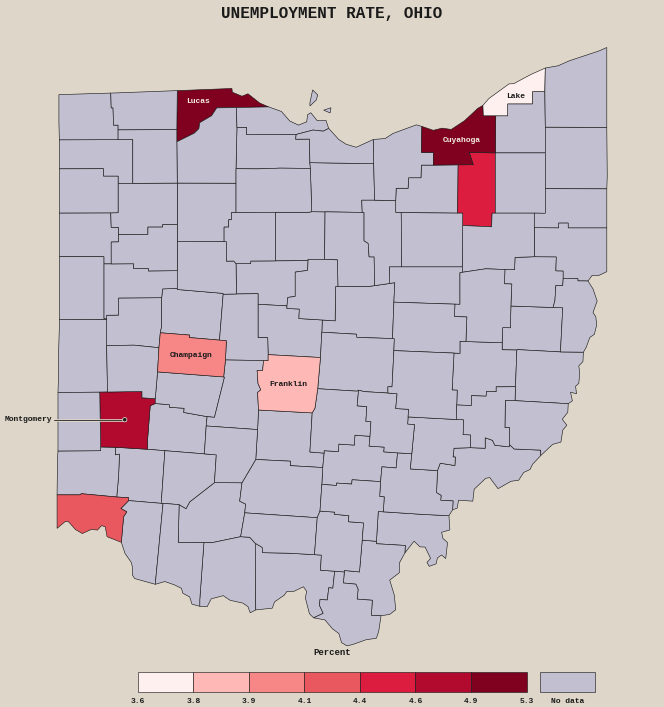

In [14]:
unemployment = pd.Series({'39035': 4.9, '39049': 3.8, '39061': 4.1, '39153': 4.4,
                          '39113': 4.6, '39095': 5.3, '39085': 3.6, '39021': 3.9})
fig = dc.county_map_chart(unemployment, title='Unemployment rate, Ohio',
                          colorbar_label='Percent')

`label_by='highest'`, `'lowest'` or `'area'` changes which counties are
named (`label_top_n` how many), and `label_counties=[...]` names them
outright.

County data from several states draw the whole country -- every county,
with the states' borders over them, Alaska and Hawaii inset below.
`state='US'` asks for it outright. Here are thirty-one of the most
populous counties, by FIPS code, with made-up values; the other 3,100
are "No data":

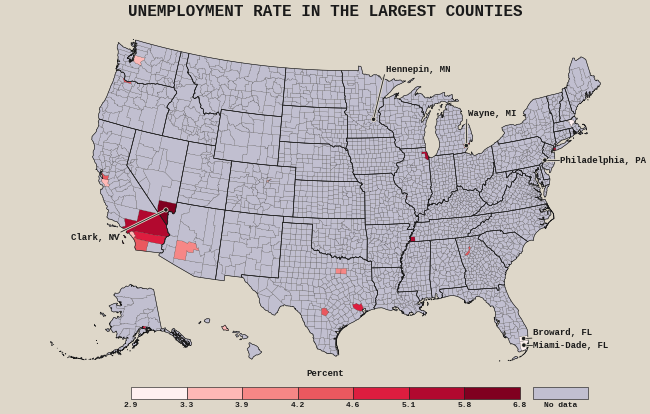

In [15]:
big_counties = {
    '06037': 5.1, '17031': 5.3, '48201': 4.6, '04013': 3.9, '06073': 4.2, '06059': 3.8,
    '12086': 2.9, '48113': 4.1, '36047': 5.8, '06065': 5.0, '53033': 3.6, '32003': 6.2,
    '48439': 4.0, '06071': 5.4, '48029': 4.2, '36081': 5.5, '26163': 6.8, '06085': 3.4,
    '12011': 3.1, '06001': 4.3, '36061': 4.9, '42101': 6.1, '25017': 3.2, '27053': 3.0,
    '13121': 4.5, '08031': 3.7, '41051': 4.4, '29510': 5.9, '47157': 5.2, '15003': 3.3,
    '02020': 4.8,
}
fig = dc.county_map_chart(big_counties, title='Unemployment rate in the largest counties',
                          colorbar_label='Percent')

## Maps of states

`state_map_chart` draws the country by state -- keyed by name, postal
code, FIPS code or Census GEO_ID. The District of Columbia, too small to
see, gets a dot; the small states of the Northeast get callouts out in
the Atlantic. These are the 2020 census's populations, rounded.

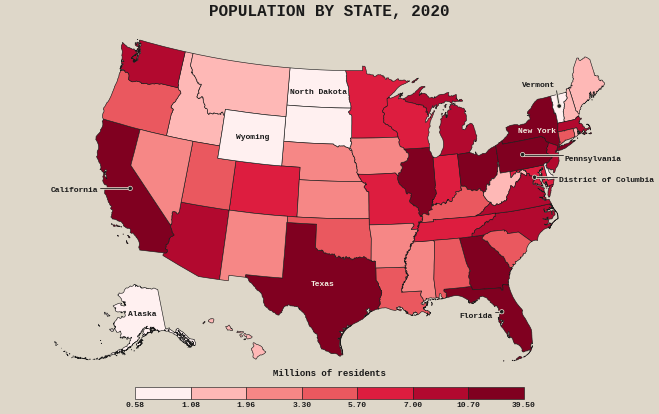

In [16]:
population = {
    'CA': 39.5, 'TX': 29.1, 'FL': 21.5, 'NY': 20.2, 'PA': 13.0, 'IL': 12.8, 'OH': 11.8,
    'GA': 10.7, 'NC': 10.4, 'MI': 10.1, 'NJ': 9.3, 'VA': 8.6, 'WA': 7.7, 'AZ': 7.2,
    'MA': 7.0, 'TN': 6.9, 'IN': 6.8, 'MD': 6.2, 'MO': 6.2, 'WI': 5.9, 'CO': 5.8, 'MN': 5.7,
    'SC': 5.1, 'AL': 5.0, 'LA': 4.7, 'KY': 4.5, 'OR': 4.2, 'OK': 4.0, 'CT': 3.6, 'UT': 3.3,
    'IA': 3.2, 'NV': 3.1, 'AR': 3.0, 'MS': 2.96, 'KS': 2.9, 'NM': 2.1, 'NE': 1.96,
    'ID': 1.84, 'WV': 1.79, 'HI': 1.46, 'NH': 1.38, 'ME': 1.36, 'RI': 1.10, 'MT': 1.08,
    'DE': 0.99, 'SD': 0.89, 'ND': 0.78, 'AK': 0.73, 'DC': 0.69, 'VT': 0.64, 'WY': 0.58,
}
fig = dc.state_map_chart(population, title='Population by state, 2020',
                         colorbar_label='Millions of residents', label_top_n=10)

## Colour-blind readers

The classic palette's crimson and green look alike to readers who can't
tell red from green -- about one man in twelve. `simulate_colorblindness`
shows how colours look to them:

In [17]:
dc.simulate_colorblindness(['#DC143C', '#00A550'], 'deuteranopia')

['#8b7e35', '#968b56']

Two olives. `set_colorblind_safe()` switches every chart's default
colours to eight of Du Bois's colours that stay distinct for readers
with any common colour-blindness, until `set_colorblind_safe(False)`.
(The maps need nothing: their scales run light to dark for everyone.)

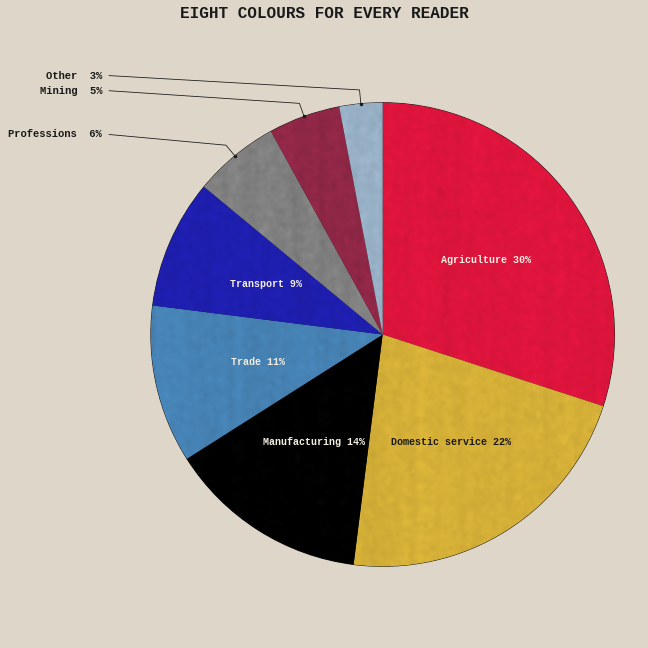

In [18]:
dc.set_colorblind_safe()
fig = dc.pie_chart({'Agriculture': 30, 'Domestic service': 22, 'Manufacturing': 14,
                    'Trade': 11, 'Transport': 9, 'Professions': 6, 'Mining': 5, 'Other': 3},
                   title='Eight colours for every reader')
dc.set_colorblind_safe(False)

## Size, fonts and texture

Every chart takes:

- `figsize=(width, height)` in inches and `dpi=` -- otherwise the chart
  picks a size to suit its data, growing taller for many rows;
- `font='...'` -- otherwise a typewriter face, the nearest common match
  for the plates' hand lettering: Liberation Mono, Courier New, Nimbus
  Mono PS or Courier, whichever is installed first, else DejaVu Sans
  Mono, which comes with matplotlib;
- `colors=[...]` (or `left_color`/`right_color`, `color`, `palette`);
- `background=` -- the cream of the original paper by default.

And `texture=False` leaves out the hand-painted grain (bar, butterfly,
area, snake and pie charts), and `hand_drawn=False` draws perfectly
smooth lines (area and spiral charts).

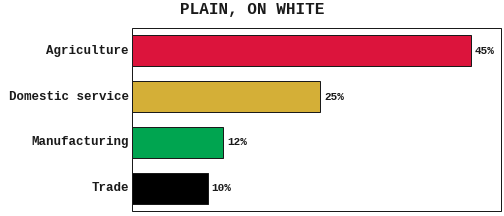

In [19]:
fig = dc.bar_chart(['Agriculture', 'Domestic service', 'Manufacturing', 'Trade'],
                   [45, 25, 12, 10], title='Plain, on white',
                   texture=False, background='#FFFFFF', figsize=(7, 3),
                   value_format='{:.0f}%')

## Many rows

Charts stay legible with a lot of data: a bar chart grows taller (up to
32 inches) so every row keeps room for its label, and past that labels
go on every few rows -- always the first and the last -- with a warning
saying how to label them all. A chart of a few hundred bars takes a few
seconds. Each category gets a colour of its own unless `colors` says
otherwise; one colour for all of them reads better here.

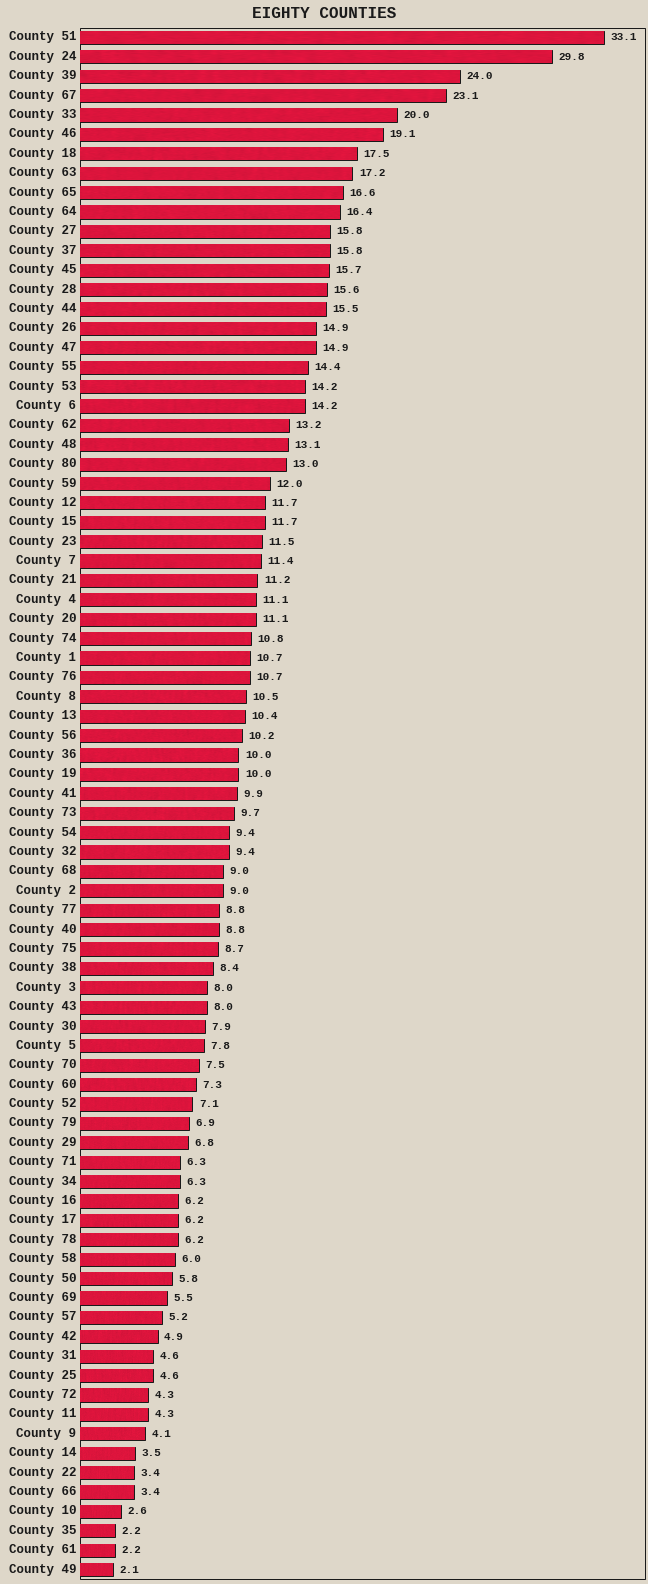

In [20]:
import numpy as np

rng = np.random.default_rng(7)
counties = pd.Series(rng.gamma(3, 4, 80).round(1), index=[f'County {i}' for i in range(1, 81)])
fig = dc.bar_chart(counties.index, counties, title='Eighty counties',
                   sort_descending=True, colors=['#DC143C'])

## Your own matplotlib charts, in the same colours

The palettes and a matplotlib theme are there for charts you draw
yourself:

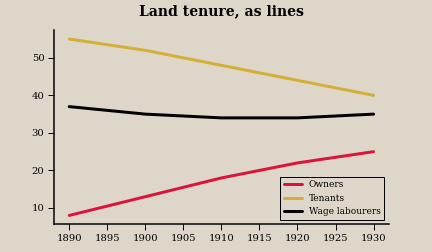

In [21]:
import matplotlib.pyplot as plt

dc.set_theme('classic')
fig, ax = plt.subplots(figsize=(6, 3.5))
for colour, (name, values) in zip(dc.get_categorical(3), tenure.items()):
    ax.plot(tenure.index, values, color=colour, linewidth=3, label=name)
ax.set_title('Land tenure, as lines')
ax.legend()
dc.reset_theme()

## Where next

- `help(dc.county_map_chart)` -- and the same for every chart -- lists
  every parameter.
- `examples/basic_usage.py` draws one of each chart, as files.
- `dubois_charts/charts/GENERAL_ENGINE_README.md` records what testing
  found in every chart, and how it was fixed.
- `dubois_charts.charts.plate51` recreates one of the original plates,
  checked pixel by pixel against the Library of Congress's scan.